# 02 -- Preprocessing & Quality Control

Raw RNA-seq quantifications cannot be fed directly into clustering or
dimensionality-reduction algorithms. This notebook walks through every
preprocessing step implemented in `src/preprocess.py`:

1. Load raw data (real GDC download if present, else the simulated cohort).
2. **Quality control**: library size, genes detected, missingness.
3. **Missing value imputation** (per-gene median).
4. **Feature filtering**: drop genes expressed in too few samples.
5. **Log2(x + 1) transformation** to stabilize variance.
6. **Outlier sample detection** via robust Mahalanobis distance in PCA space.
7. **Variance-based feature selection** (top-N most variable genes by MAD).
8. **Z-score normalization** (gene-wise).
9. **Batch-effect assessment** (sequencing plate vs. PCA variance).


In [1]:
import sys
from pathlib import Path

REPO_ROOT = Path.cwd().parent if (Path.cwd() / ".." / "src").exists() else Path.cwd()
sys.path.insert(0, str(REPO_ROOT))

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from IPython.display import Image, display

from src.config import load_config
from src.logging_config import setup_logging

setup_logging()
cfg = load_config(REPO_ROOT / "config.yaml")
FIGURES = REPO_ROOT / "figures"
RESULTS = REPO_ROOT / "results"
REPORTS = REPO_ROOT / "reports"
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
print(f"Repo root: {REPO_ROOT}")
print(f"Cancer type: {cfg['project']['cancer_type']}")


Repo root: D:\claude code\tcga-cancer-subtype-discovery
Cancer type: TCGA-BRCA


In [2]:
from src.preprocess import (
    load_raw_data, qc_report, impute_missing, filter_low_expression_genes,
    log_transform, detect_outlier_samples, select_variable_genes,
    zscore_normalize, assess_batch_effect, correct_batch_mean_centering,
)
from src import visualization as viz

expr, clinical = load_raw_data(cfg)
print(f"Raw matrix: {expr.shape[0]} genes x {expr.shape[1]} samples")
clinical.head()


2026-07-28 15:04:59 | INFO     | src.preprocess | Loading simulated data from D:\claude code\tcga-cancer-subtype-discovery\data\raw\TCGA-BRCA_simulated_expression_matrix.tsv


Raw matrix: 4000 genes x 500 samples


,true_subtype,sequencing_plate,age_at_index,gender,ajcc_pathologic_stage,tumor_grade,vital_status,days_to_event,event_observed
SIM-BRCA-0000,Luminal B,Plate_C,57.1,female,Stage IIB,G1,Dead,770.0,1
SIM-BRCA-0001,HER2-enriched,Plate_A,65.7,male,Stage IA,G1,Dead,1209.0,1
SIM-BRCA-0002,Basal-like,Plate_B,67.2,female,Stage IIB,G3,Dead,24.0,1
SIM-BRCA-0003,Luminal A,Plate_C,55.5,female,Stage IIA,G1,Alive,2268.0,0
SIM-BRCA-0004,Luminal B,Plate_A,53.4,female,Stage IIIA,G2,Alive,3308.0,0


## 2.1 Quality control: library size, genes detected, missingness

In [3]:
qc = qc_report(expr)
print("Library size summary:", qc["library_size_summary"])
print("Genes detected summary:", qc["genes_detected_summary"])
print(f"Total missing values: {qc['total_missing_values']} ({qc['pct_missing']:.4f}%)")


2026-07-28 15:04:59 | INFO     | src.preprocess | QC: 4000 genes x 500 samples | 0.1028% missing | median library size 880248 | median genes detected 3980


Library size summary: {'count': 500.0, 'mean': 1063577.5310488204, 'std': 953132.0696469698, 'min': 57760.32629821714, '25%': 801488.2209748591, '50%': 880247.6646096471, '75%': 1026510.4499500849, 'max': 14122662.54955995}
Genes detected summary: {'count': 500.0, 'mean': 3971.346, 'std': 60.46418874210156, 'min': 3449.0, '25%': 3974.0, '50%': 3980.0, '75%': 3984.0, 'max': 3999.0}
Total missing values: 2056 (0.1028%)


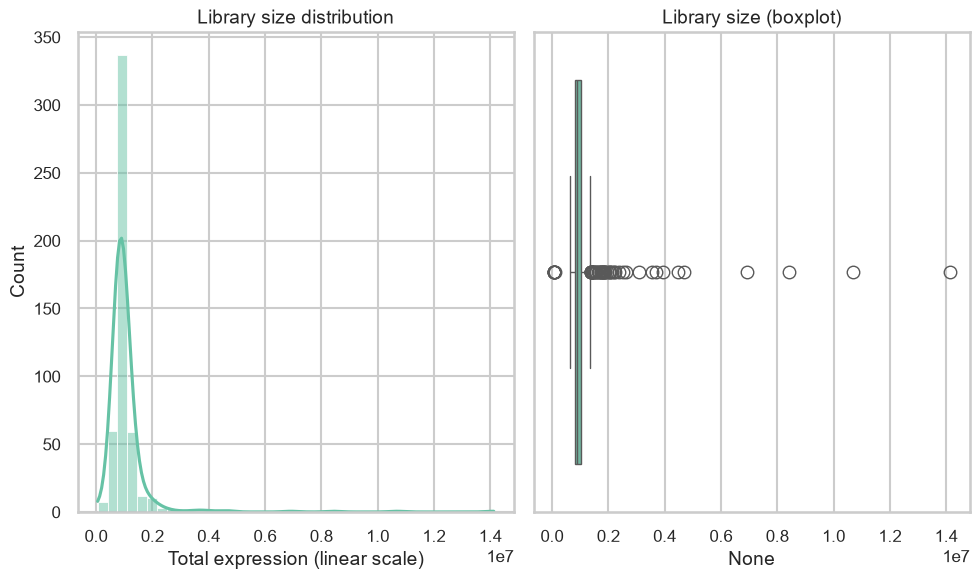

In [4]:
fig = viz.plot_library_size_distribution(qc["library_size"], FIGURES / "eda" / "library_size_distribution.png")


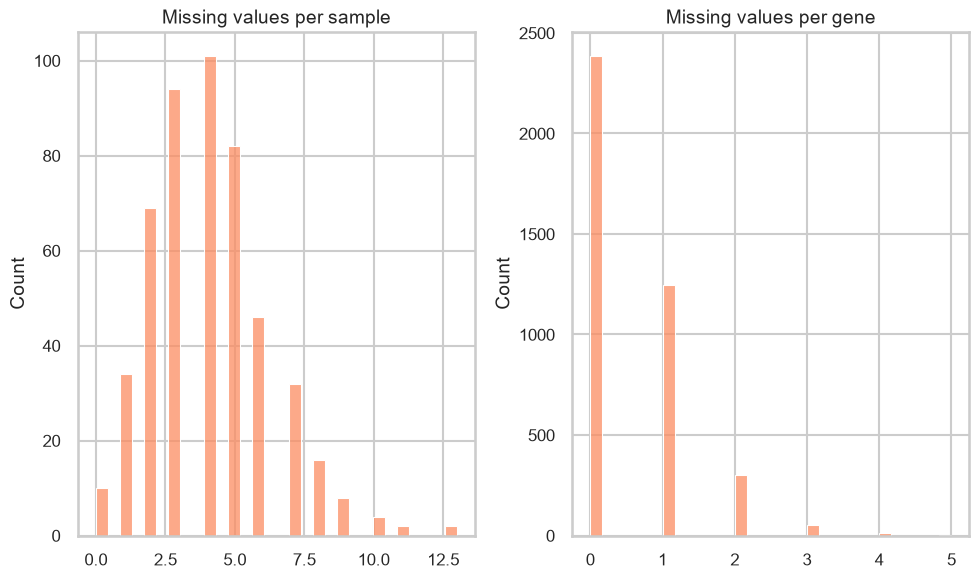

In [5]:
fig = viz.plot_missingness(qc["missing_per_sample"], qc["missing_per_gene"], FIGURES / "eda" / "missingness.png")


## 2.2 Missing value imputation + gene filtering

In [6]:
expr_imputed = impute_missing(expr)
expr_filtered = filter_low_expression_genes(expr_imputed, cfg["preprocessing"]["min_samples_expressing"])
print(f"After filtering: {expr_filtered.shape[0]} genes retained")


2026-07-28 15:05:00 | INFO     | src.preprocess | Imputing 2056 missing values with per-gene median.


2026-07-28 15:05:00 | INFO     | src.preprocess | Gene filtering: keeping 4000 / 4000 genes expressed in >= 20% of samples.


After filtering: 4000 genes retained


## 2.3 Log2 transformation

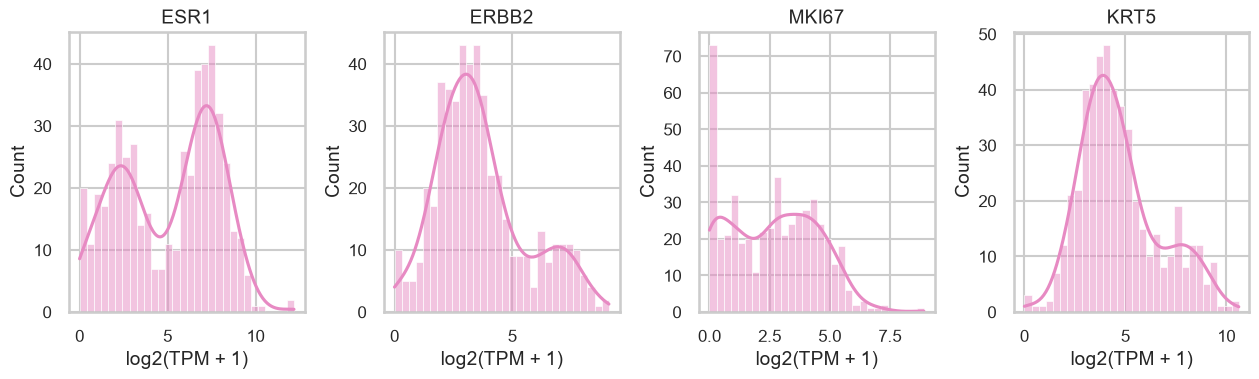

In [7]:
log_expr = log_transform(expr_filtered, cfg["preprocessing"]["log_transform"])
marker_genes_present = [g for g in ["ESR1", "ERBB2", "MKI67", "KRT5"] if g in log_expr.index]
fig = viz.plot_feature_distributions(log_expr, marker_genes_present, FIGURES / "eda" / "marker_gene_distributions.png")


## 2.4 Outlier sample detection

Robust Mahalanobis distance (Minimum Covariance Determinant estimator) in
the top-10 PCA space flags samples that are extreme multivariate outliers --
here, by construction, the synthetic cohort includes ~2% globally-scaled
outlier samples (see `src/simulate.py`) to give this step something
genuine to detect.

In [8]:
outliers, distances = detect_outlier_samples(log_expr, z_threshold=cfg["preprocessing"]["outlier_zscore_threshold"])
print(f"Flagged {len(outliers)} outlier samples: {outliers}")
distances.describe()


2026-07-28 15:05:01 | INFO     | src.preprocess | Outlier detection: flagged 11 / 500 samples (robust z > 3.5).


Flagged 11 outlier samples: ['SIM-BRCA-0017', 'SIM-BRCA-0080', 'SIM-BRCA-0206', 'SIM-BRCA-0225', 'SIM-BRCA-0241', 'SIM-BRCA-0249', 'SIM-BRCA-0282', 'SIM-BRCA-0386', 'SIM-BRCA-0391', 'SIM-BRCA-0460', 'SIM-BRCA-0478']


count    500.000000
mean       3.876554
std        5.320902
min        1.149885
25%        2.639976
50%        3.141407
75%        3.596458
max       42.124509
Name: mahalanobis_distance, dtype: float64

## 2.5 Variance-based feature selection

2026-07-28 15:05:02 | INFO     | src.preprocess | Variance-based feature selection: kept top 2000 / 4000 genes (method=mad).


Selected 2000 top-variable genes for downstream analysis.


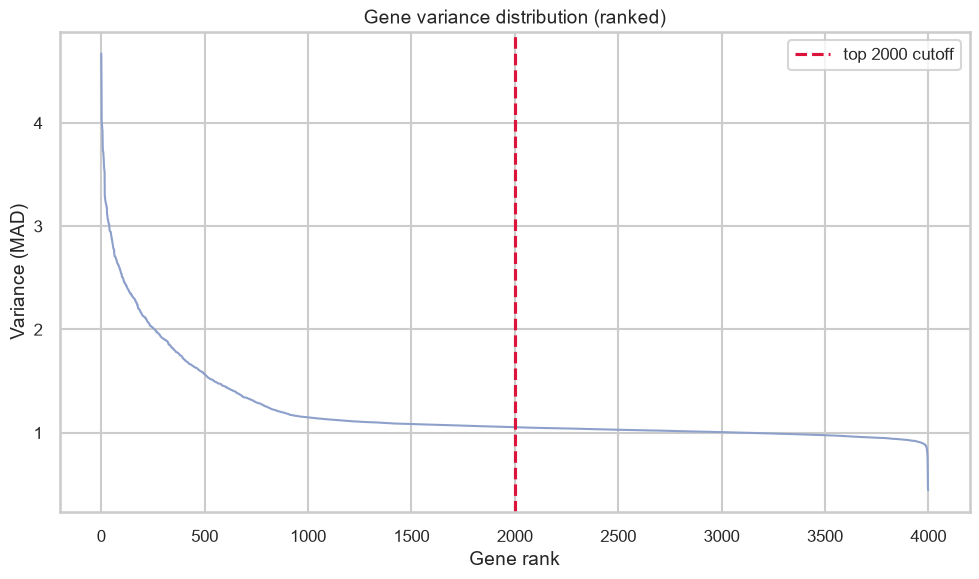

In [9]:
variable_expr, gene_variance = select_variable_genes(
    log_expr, top_n=cfg["preprocessing"]["top_n_variable_genes"], method=cfg["preprocessing"]["variance_method"]
)
fig = viz.plot_gene_variance_distribution(gene_variance, cfg["preprocessing"]["top_n_variable_genes"], FIGURES / "eda" / "gene_variance_distribution.png")
print(f"Selected {variable_expr.shape[0]} top-variable genes for downstream analysis.")


## 2.6 Z-score normalization

In [10]:
scaled_expr = zscore_normalize(variable_expr)
scaled_expr.iloc[:5, :5]


,SIM-BRCA-0000,SIM-BRCA-0001,SIM-BRCA-0002,SIM-BRCA-0003,SIM-BRCA-0004
gene_name,,,,,
PPP1CC,0.936410,-1.444313,-1.402552,1.410685,1.027900
RBM22,1.329050,-0.398719,0.807417,-1.331196,-0.443399
EXTL2,-0.976004,-0.753338,-0.848400,0.913883,0.366728
NPFFR1,-1.261124,0.748464,-0.839368,1.659270,-0.511288
CD14,0.364228,-0.105142,1.712600,0.095362,1.112752


## 2.7 Batch-effect assessment

We quantify what fraction of each principal component's variance is
associated with `sequencing_plate` (a simulated nuisance covariate standing
in for real-world sequencing batch/center effects) via one-way ANOVA
eta-squared -- the same diagnostic logic used by tools like `pvca`.

In [11]:
if "sequencing_plate" in clinical.columns:
    batch_report = assess_batch_effect(scaled_expr, clinical["sequencing_plate"])
    display(batch_report)
    print("\nInterpretation: eta_squared_batch close to 0 means that PC is NOT")
    print("driven by sequencing plate; values approaching 1 would indicate a")
    print("serious batch confound requiring correction (e.g. ComBat) before")
    print("any biological interpretation of that component.")


,PC,eta_squared_batch,f_stat,p_value
0,PC1,0.010436,2.620695,0.073758
1,PC2,0.001621,0.403489,0.668204
2,PC3,0.003158,0.787242,0.455665
3,PC4,0.004754,1.187010,0.305996
4,PC5,0.000402,0.099839,0.905002



Interpretation: eta_squared_batch close to 0 means that PC is NOT
driven by sequencing plate; values approaching 1 would indicate a
serious batch confound requiring correction (e.g. ComBat) before
any biological interpretation of that component.


**Batch-effect discussion.** In this cohort, plate explains only a small,
non-significant fraction of variance on the leading PCs (see table above) --
the injected plate effect is real but confined to a small gene subset (see
`src/simulate.py`), consistent with a well-controlled real sequencing batch
rather than a dominant confound. `src.preprocess.correct_batch_mean_centering`
is available as a lightweight correction (per-batch mean-centering) if a
real dataset shows a stronger association; production pipelines should
prefer `ComBat`/`limma::removeBatchEffect` for real multi-center TCGA data.

## Summary

In [12]:
import json
with open(REPORTS / "preprocessing_summary.json") as fh:
    print(json.dumps(json.load(fh), indent=2))


{
  "n_genes_raw": 4000,
  "n_samples_raw": 500,
  "pct_missing_raw": 0.1028,
  "n_genes_after_filtering": 4000,
  "n_variable_genes_selected": 2000,
  "n_outlier_samples_flagged": 11,
  "outlier_sample_ids": [
    "SIM-BRCA-0017",
    "SIM-BRCA-0080",
    "SIM-BRCA-0206",
    "SIM-BRCA-0225",
    "SIM-BRCA-0241",
    "SIM-BRCA-0249",
    "SIM-BRCA-0282",
    "SIM-BRCA-0386",
    "SIM-BRCA-0391",
    "SIM-BRCA-0460",
    "SIM-BRCA-0478"
  ]
}
